# Simulación y probabilidad · Monte Carlo

El método de Monte Carlo estima un valor como la media de muchas simulaciones aleatorias. Si $X_1, \dots, X_n$ son muestras independientes de $X$, la media $\bar X_n = \frac{1}{n}\sum_{i=1}^{n} X_i$ tiende a $E[X]$ (ley de los grandes números) y su error típico es $\sigma / \sqrt{n}$: para ganar una cifra decimal hay que multiplicar las muestras por 100. Cada simulación vectorizada con `numpy` cuesta $O(n)$. Las semillas son fijas para que los resultados se puedan reproducir.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

## 1. Estimar π

Lanzar puntos uniformes en el cuadrado $[-1, 1]^2$: la fracción que cae dentro del círculo unidad tiende a $\pi/4$. Dibujar 2000 puntos coloreando los de dentro y estimar π con $10^6$ puntos.

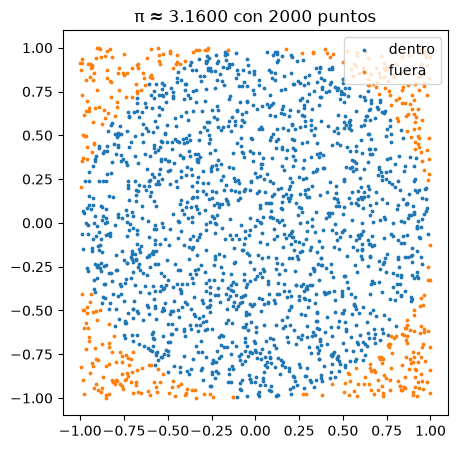

π ≈ 3.14032   error 0.00128


In [2]:
def estimar_pi(n, rng):
    x, y = rng.uniform(-1, 1, (2, n))
    return 4 * np.mean(x**2 + y**2 <= 1)


rng = np.random.default_rng(1)
x, y = rng.uniform(-1, 1, (2, 2000))
dentro = x**2 + y**2 <= 1
plt.figure(figsize=(5, 5))
plt.scatter(x[dentro], y[dentro], s=3, label="dentro")
plt.scatter(x[~dentro], y[~dentro], s=3, label="fuera")
plt.gca().set_aspect("equal")
plt.title(f"π ≈ {4 * dentro.mean():.4f} con 2000 puntos")
plt.legend(loc="upper right")
plt.show()

estimacion = estimar_pi(10**6, rng)
print(f"π ≈ {estimacion:.5f}   error {abs(estimacion - math.pi):.5f}")
assert abs(estimacion - math.pi) < 0.01

## 2. Integrales

Como $\int_a^b f(x)\,dx = (b-a)\,E[f(U)]$ con $U$ uniforme en $[a, b]$, la integral se estima con la media de $f$ en puntos aleatorios, y su error típico con la desviación típica de la muestra entre $\sqrt n$. Escribir `integral(f, a, b, n, rng)`, que devuelva la estimación y su error típico, y probarla con $\int_0^\pi \sin x\,dx = 2$, $\int_0^1 e^{-x^2}dx = \frac{\sqrt\pi}{2}\operatorname{erf}(1)$ y $\int_0^1 \frac{4}{1+x^2}\,dx = \pi$.

In [3]:
def integral(f, a, b, n, rng):
    valores = (b - a) * f(rng.uniform(a, b, n))
    return valores.mean(), valores.std(ddof=1) / math.sqrt(n)


rng = np.random.default_rng(2)
casos = [
    ("sen x en [0, π]", np.sin, 0, math.pi, 2),
    ("exp(-x²) en [0, 1]", lambda x: np.exp(-x**2), 0, 1, math.sqrt(math.pi) / 2 * math.erf(1)),
    ("4/(1+x²) en [0, 1]", lambda x: 4 / (1 + x**2), 0, 1, math.pi),
]
for nombre, f, a, b, exacto in casos:
    estimacion, error = integral(f, a, b, 10**5, rng)
    print(f"{nombre:20} {estimacion:.5f} ± {error:.5f}   exacto {exacto:.5f}")
    assert abs(estimacion - exacto) < 4 * error

sen x en [0, π]      1.99749 ± 0.00306   exacto 2.00000
exp(-x²) en [0, 1]   0.74670 ± 0.00064   exacto 0.74682
4/(1+x²) en [0, 1]   3.14287 ± 0.00203   exacto 3.14159


## 3. Error frente al número de muestras

Repetir 40 veces la estimación de π para cada $n$ entre $10$ y $10^6$ y dibujar en escala logarítmica los errores y la raíz del error cuadrático medio junto a la curva teórica $\sigma / \sqrt{n}$, con $\sigma = 4\sqrt{p(1-p)}$ y $p = \pi/4$. Ajustar una recta a los puntos: su pendiente debe salir cerca de $-1/2$.

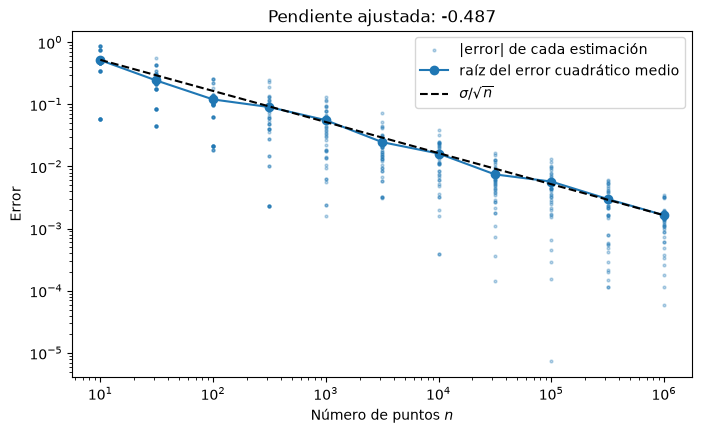

In [4]:
rng = np.random.default_rng(3)
tamanos = np.logspace(1, 6, 11).astype(int)
repeticiones = 40
errores = np.array([[estimar_pi(n, rng) - math.pi for _ in range(repeticiones)] for n in tamanos])
rmse = np.sqrt((errores**2).mean(axis=1))
p = math.pi / 4
teorico = 4 * math.sqrt(p * (1 - p)) / np.sqrt(tamanos)
pendiente, _ = np.polyfit(np.log(tamanos), np.log(rmse), 1)

plt.figure(figsize=(8, 4.5))
plt.scatter(np.repeat(tamanos, repeticiones), np.abs(errores).ravel(), s=4, alpha=0.3, label="|error| de cada estimación")
plt.plot(tamanos, rmse, "o-", label="raíz del error cuadrático medio")
plt.plot(tamanos, teorico, "k--", label=r"$\sigma/\sqrt{n}$")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Número de puntos $n$")
plt.ylabel("Error")
plt.title(f"Pendiente ajustada: {pendiente:.3f}")
plt.legend()
plt.show()
assert -0.6 < pendiente < -0.4

## 4. Problema de Monty Hall

Detrás de una de tres puertas hay un coche. El concursante elige una, el presentador abre otra sin premio y le ofrece cambiar. Simular partidas con cada estrategia y generalizar a $k$ puertas en las que el presentador abre solo una: quedándose se gana con probabilidad $\frac1k$ y cambiando a otra puerta cerrada al azar, con $\frac{k-1}{k(k-2)}$ (2/3 con tres puertas). Comprobar las fórmulas enumerando todos los casos con fracciones exactas.

In [5]:
import random
from fractions import Fraction


def partida(k, cambiar, rng):
    coche, eleccion = rng.randrange(k), rng.randrange(k)
    abierta = rng.choice([p for p in range(k) if p not in (coche, eleccion)])
    if cambiar:
        eleccion = rng.choice([p for p in range(k) if p not in (eleccion, abierta)])
    return eleccion == coche


def probabilidad_exacta(k, cambiar):
    total = Fraction(0)
    for coche in range(k):
        for eleccion in range(k):
            abiertas = [p for p in range(k) if p not in (coche, eleccion)]
            for abierta in abiertas:
                caso = Fraction(1, k * k * len(abiertas))
                if cambiar:
                    otras = [p for p in range(k) if p not in (eleccion, abierta)]
                    total += caso * Fraction(otras.count(coche), len(otras))
                else:
                    total += caso * (eleccion == coche)
    return total


rng = random.Random(4)
n = 30_000
print(" k   quedarse   cambiar   exacta (cambiar)")
for k in (3, 4, 5, 10):
    quedarse = sum(partida(k, False, rng) for _ in range(n)) / n
    cambiar = sum(partida(k, True, rng) for _ in range(n)) / n
    exacta = probabilidad_exacta(k, True)
    print(f"{k:2}   {quedarse:.4f}     {cambiar:.4f}    {exacta} = {float(exacta):.4f}")
    assert probabilidad_exacta(k, False) == Fraction(1, k) and exacta == Fraction(k - 1, k * (k - 2))
    assert abs(quedarse - 1 / k) < 0.015 and abs(cambiar - exacta) < 0.015

 k   quedarse   cambiar   exacta (cambiar)
 3   0.3300     0.6669    2/3 = 0.6667
 4   0.2481     0.3751    3/8 = 0.3750
 5   0.2028     0.2658    4/15 = 0.2667


10   0.1006     0.1100    9/80 = 0.1125


## 5. Problema del cumpleaños

¿Cuántas personas hacen falta para que la probabilidad de que dos cumplan años el mismo día supere 1/2? Simularlo con 20 000 grupos de cada tamaño, de 1 a 60 personas (365 días equiprobables), compararlo con la fórmula exacta $1 - \prod_{i=0}^{k-1} \frac{365-i}{365}$ y dibujar ambas curvas.

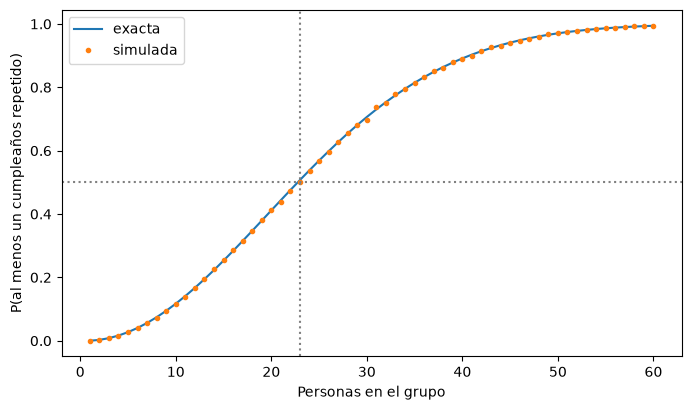

Con 23 personas: exacta 0.5073, simulada 0.5022


In [6]:
rng = np.random.default_rng(5)
grupos = np.arange(1, 61)
simulada = []
for k in grupos:
    dias = np.sort(rng.integers(365, size=(20_000, k)), axis=1)
    simulada.append(np.mean((np.diff(dias, axis=1) == 0).any(axis=1)))
simulada = np.array(simulada)
exacta = 1 - np.cumprod((365 - np.arange(60)) / 365)
umbral = grupos[np.argmax(exacta > 0.5)]

plt.figure(figsize=(8, 4.5))
plt.plot(grupos, exacta, label="exacta")
plt.plot(grupos, simulada, ".", label="simulada")
plt.axhline(0.5, color="gray", linestyle=":")
plt.axvline(umbral, color="gray", linestyle=":")
plt.xlabel("Personas en el grupo")
plt.ylabel("P(al menos un cumpleaños repetido)")
plt.legend()
plt.show()
print(f"Con {umbral} personas: exacta {exacta[umbral - 1]:.4f}, simulada {simulada[umbral - 1]:.4f}")
assert umbral == 23 and np.abs(simulada - exacta).max() < 0.02

## 6. La aguja de Buffon

Se dejan caer agujas de longitud $l$ sobre un suelo con rayas paralelas separadas $t \ge l$. Una aguja corta una raya si la distancia $x$ de su centro a la raya más cercana cumple $x \le \frac{l}{2}\sin\theta$, lo que ocurre con probabilidad $p = \frac{2l}{\pi t}$, así que $\pi \approx \frac{2l}{\hat p\, t}$. Para no usar π al generar el ángulo, obtener $\sin\theta$ y $\cos\theta$ a partir de un punto aleatorio del semicírculo unidad aceptado por rechazo. Dibujar 100 agujas y estimar π con $10^6$.

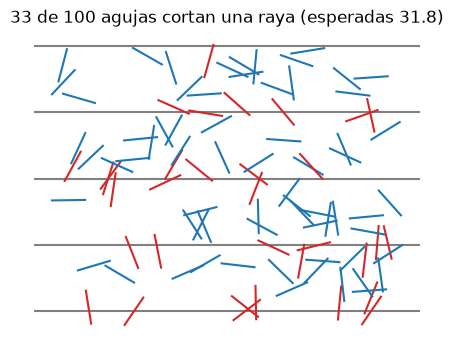

π ≈ 3.13898   error 0.00261


In [7]:
def direcciones(n, rng):
    u, v = rng.uniform(-1, 1, 2 * n), rng.uniform(0, 1, 2 * n)
    r = np.hypot(u, v)
    validos = (r <= 1) & (r > 0)
    assert validos.sum() >= n
    return (u[validos] / r[validos])[:n], (v[validos] / r[validos])[:n]


def buffon(n, l, t, rng):
    _, seno = direcciones(n, rng)
    x = rng.uniform(0, t / 2, n)
    p = np.mean(x <= l / 2 * seno)
    return 2 * l / (p * t)


rng = np.random.default_rng(6)
l, t = 1, 2
coseno, seno = direcciones(100, rng)
cx, cy = rng.uniform(0, 10, 100), rng.uniform(0, 4 * t, 100)
x1, x2 = cx - l / 2 * coseno, cx + l / 2 * coseno
y1, y2 = cy - l / 2 * seno, cy + l / 2 * seno
corta = np.floor(y1 / t) != np.floor(y2 / t)

plt.figure(figsize=(8, 4))
for k in range(5):
    plt.axhline(k * t, color="gray")
for a, b, c, d, color in zip(x1, x2, y1, y2, np.where(corta, "tab:red", "tab:blue")):
    plt.plot([a, b], [c, d], color=color)
plt.gca().set_aspect("equal")
plt.title(f"{corta.sum()} de 100 agujas cortan una raya (esperadas {100 * 2 * l / (math.pi * t):.1f})")
plt.axis("off")
plt.show()

estimacion = buffon(10**6, l, t, rng)
print(f"π ≈ {estimacion:.5f}   error {abs(estimacion - math.pi):.5f}")
assert abs(estimacion - math.pi) < 0.02

## 7. Volumen de una bola en $d$ dimensiones

Estimar el volumen de la bola unidad en $d$ dimensiones como la fracción de puntos del cubo $[-1, 1]^d$ que caen dentro por el volumen del cubo, $2^d$, y compararlo con la fórmula $V_d = \frac{\pi^{d/2}}{\Gamma(d/2 + 1)}$ para $d = 1..12$ con $2 \cdot 10^5$ puntos. Dibujar los volúmenes y el error relativo: la fracción de puntos que caen dentro se hace tan pequeña que cada vez hacen falta más muestras (la maldición de la dimensión).

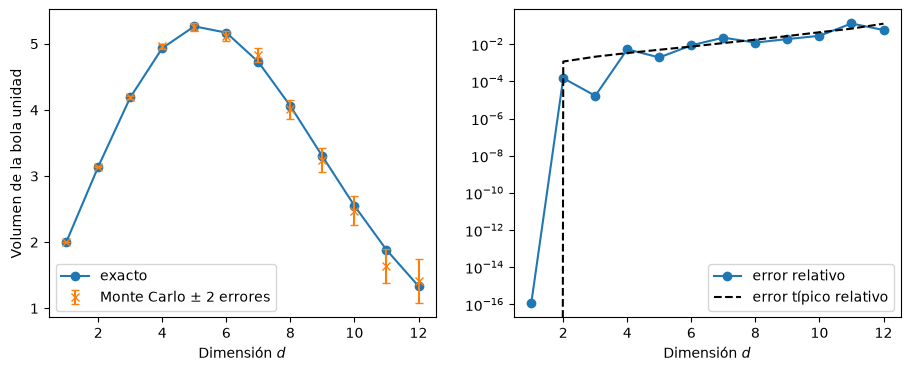

d =  2: 3.1421 (exacto 3.1416), dentro 7.85e-01 del cubo
d =  3: 4.1887 (exacto 4.1888), dentro 5.24e-01 del cubo
d =  6: 5.1226 (exacto 5.1677), dentro 8.07e-02 del cubo
d = 12: 1.4131 (exacto 1.3353), dentro 3.26e-04 del cubo


In [8]:
rng = np.random.default_rng(7)
n = 200_000
dimensiones = np.arange(1, 13)
estimado, exacto, error_tipico = [], [], []
for d in dimensiones:
    puntos = rng.uniform(-1, 1, (n, d))
    p = np.mean((puntos**2).sum(axis=1) <= 1)
    estimado.append(2**d * p)
    error_tipico.append(2**d * math.sqrt(p * (1 - p) / n))
    exacto.append(math.pi ** (d / 2) / math.gamma(d / 2 + 1))
estimado, exacto, error_tipico = map(np.array, (estimado, exacto, error_tipico))
assert np.all(np.abs(estimado - exacto) <= 4 * error_tipico + 1e-9)

fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(11, 4))
eje1.plot(dimensiones, exacto, "o-", label="exacto")
eje1.errorbar(dimensiones, estimado, yerr=2 * error_tipico, fmt="x", capsize=3, label="Monte Carlo ± 2 errores")
eje1.set_xlabel("Dimensión $d$")
eje1.set_ylabel("Volumen de la bola unidad")
eje1.legend()
eje2.semilogy(dimensiones, np.abs(estimado - exacto) / exacto, "o-", label="error relativo")
eje2.semilogy(dimensiones, error_tipico / exacto, "k--", label="error típico relativo")
eje2.set_xlabel("Dimensión $d$")
eje2.legend()
plt.show()
for d in (2, 3, 6, 12):
    print(f"d = {d:2}: {estimado[d - 1]:.4f} (exacto {exacto[d - 1]:.4f}), dentro {exacto[d - 1] / 2**d:.2e} del cubo")

## 8. Ruina del jugador

Un jugador empieza con $k$ euros y en cada jugada gana o pierde 1 € con probabilidades $p$ y $q = 1 - p$, hasta arruinarse o llegar a $N$. La probabilidad de llegar a $N$ es $\frac{k}{N}$ si $p = \frac12$ y $\frac{1 - (q/p)^k}{1 - (q/p)^N}$ si no; con $p = \frac12$ la duración media es $k(N - k)$. Simular a la vez 5000 partidas para cada $k$ con $N = 20$ y $p \in \{0{,}5;\ 0{,}48;\ 0{,}45\}$, dibujar la probabilidad de ganar frente a la exacta y comprobar la duración media.

p = 0,5, k =  1: duración media   18.2   exacta 19
p = 0,5, k =  5: duración media   76.5   exacta 75
p = 0,5, k = 10: duración media   99.5   exacta 100


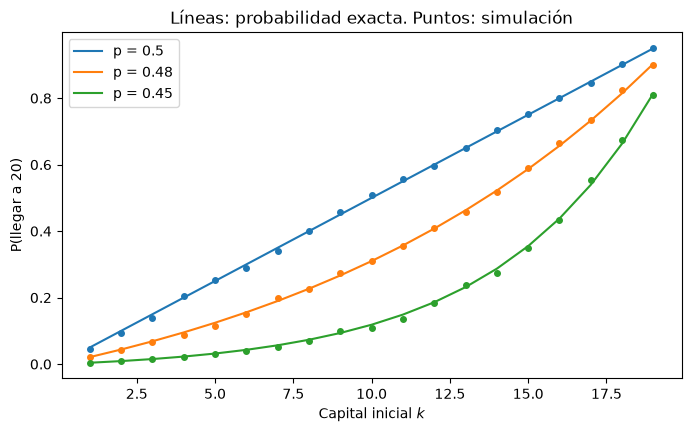

In [9]:
def ruina(capital_inicial, N, p, rng):
    capital = np.array(capital_inicial)
    duracion = np.zeros(capital.size, dtype=int)
    activas = (capital > 0) & (capital < N)
    while activas.any():
        indices = np.flatnonzero(activas)
        capital[indices] += np.where(rng.random(indices.size) < p, 1, -1)
        duracion[indices] += 1
        activas[indices] = (capital[indices] > 0) & (capital[indices] < N)
    return capital == N, duracion


def probabilidad_ganar(k, N, p):
    if p == 0.5:
        return k / N
    r = (1 - p) / p
    return (1 - r**k) / (1 - r**N)


rng = np.random.default_rng(8)
N, partidas = 20, 5000
ks = np.arange(1, N)
plt.figure(figsize=(8, 4.5))
for p in (0.5, 0.48, 0.45):
    gana, duracion = ruina(np.repeat(ks, partidas), N, p, rng)
    simulada = gana.reshape(len(ks), partidas).mean(axis=1)
    exacta = probabilidad_ganar(ks, N, p)
    assert np.abs(simulada - exacta).max() < 0.03
    plt.plot(ks, exacta, label=f"p = {p}")
    plt.plot(ks, simulada, "o", color=plt.gca().lines[-1].get_color(), markersize=4)
    if p == 0.5:
        duraciones = duracion.reshape(len(ks), partidas)
        media, error = duraciones.mean(axis=1), duraciones.std(axis=1, ddof=1) / math.sqrt(partidas)
        assert np.all(np.abs(media - ks * (N - ks)) < 4 * error)
        for k in (1, 5, 10):
            print(f"p = 0,5, k = {k:2}: duración media {media[k - 1]:6.1f}   exacta {k * (N - k)}")
plt.xlabel("Capital inicial $k$")
plt.ylabel(f"P(llegar a {N})")
plt.title("Líneas: probabilidad exacta. Puntos: simulación")
plt.legend()
plt.show()

## 9. Intervalos de confianza

Con $n$ muestras, el intervalo $\bar X_n \pm 1{,}96\,\frac{s}{\sqrt n}$ contiene el valor real con una probabilidad cercana al 95 %. Repetir 1000 veces la estimación de $\int_0^1 e^{-x^2}dx$ con `integral` y $n = 1000$, contar cuántos intervalos contienen el valor exacto y dibujar los 50 primeros.

Intervalos que contienen el valor exacto: 96.0%


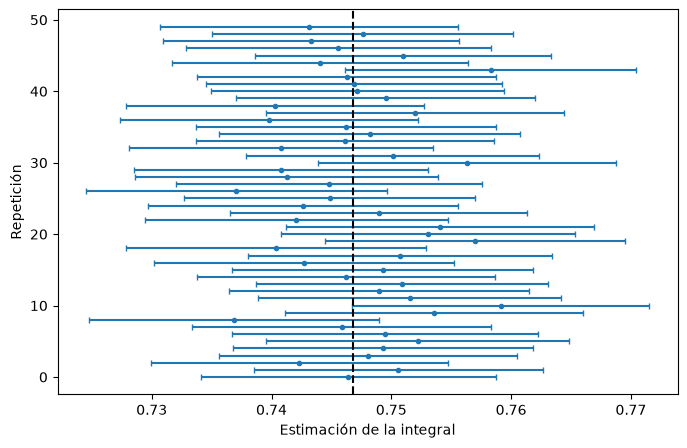

In [10]:
rng = np.random.default_rng(9)
exacto = math.sqrt(math.pi) / 2 * math.erf(1)
estimaciones = np.array([integral(lambda x: np.exp(-x**2), 0, 1, 1000, rng) for _ in range(1000)])
centro, radio = estimaciones[:, 0], 1.96 * estimaciones[:, 1]
acierta = np.abs(centro - exacto) <= radio
print(f"Intervalos que contienen el valor exacto: {acierta.mean():.1%}")
assert 0.93 < acierta.mean() < 0.97

plt.figure(figsize=(8, 5))
for i in range(50):
    plt.errorbar(centro[i], i, xerr=radio[i], fmt="o", markersize=3, capsize=2,
                 color="tab:blue" if acierta[i] else "tab:red")
plt.axvline(exacto, color="black", linestyle="--")
plt.xlabel("Estimación de la integral")
plt.ylabel("Repetición")
plt.show()

## 10. Sucesos raros: muestreo por importancia

Para estimar $P(Z > 4) \approx 3{,}17 \cdot 10^{-5}$ con $Z$ normal estándar, el método directo apenas ve unos pocos casos en $10^5$ muestras. Con muestreo por importancia se muestrea $Y \sim N(4, 1)$, donde el suceso es frecuente, y se corrige con el cociente de densidades $w(y) = \frac{\varphi(y)}{\varphi(y-4)} = e^{8 - 4y}$, porque $P(Z > 4) = E[\mathbf{1}_{Y > 4}\, w(Y)]$. Comparar ambas estimaciones y sus errores con el valor exacto $\frac12 \operatorname{erfc}(4/\sqrt2)$ y dibujar cómo evoluciona cada una con el número de muestras.

Directo      3.0000e-05 ± 1.7e-05   error relativo   5.28%
Importancia  3.1411e-05 ± 2.1e-07   error relativo   0.82%
Exacto       3.1671e-05


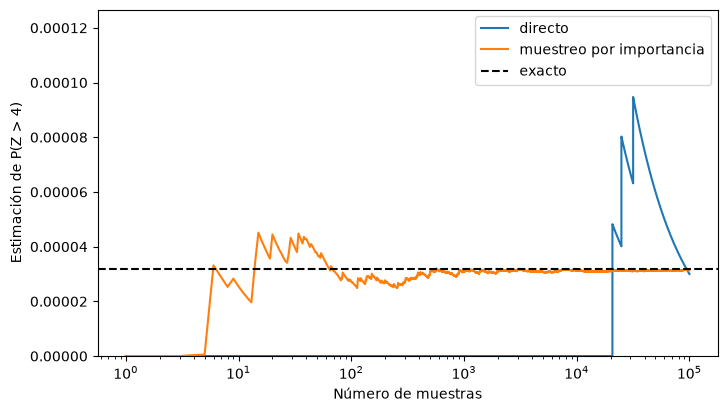

In [11]:
rng = np.random.default_rng(10)
n = 10**5
exacto = 0.5 * math.erfc(4 / math.sqrt(2))
directo = (rng.standard_normal(n) > 4).astype(float)
y = rng.normal(4, 1, n)
importancia = (y > 4) * np.exp(8 - 4 * y)

for nombre, muestras in (("Directo", directo), ("Importancia", importancia)):
    estimacion, error = muestras.mean(), muestras.std(ddof=1) / math.sqrt(n)
    print(f"{nombre:12} {estimacion:.4e} ± {error:.1e}   error relativo {abs(estimacion - exacto) / exacto:7.2%}")
print(f"{'Exacto':12} {exacto:.4e}")
assert abs(importancia.mean() - exacto) / exacto < 0.02

pasos = np.arange(1, n + 1)
plt.figure(figsize=(8, 4.5))
plt.plot(pasos, np.cumsum(directo) / pasos, label="directo")
plt.plot(pasos, np.cumsum(importancia) / pasos, label="muestreo por importancia")
plt.axhline(exacto, color="black", linestyle="--", label="exacto")
plt.xscale("log")
plt.ylim(0, 4 * exacto)
plt.xlabel("Número de muestras")
plt.ylabel("Estimación de P(Z > 4)")
plt.legend()
plt.show()